# Random Forest Classifier - Diabetes Classification

This is Classification Model 6 (Review 2 Part B), written to continue the code-and-cell sequence of `classification5_SVM.ipynb`.

## Dataset consistency contract
- **Same source dataset as Classification 1–5:** `../dataset/diabetes_prediction_dataset_2000.csv`
- **Target column:** `diabetes`
- **Split:** stratified 80:20 train/test, `random_state=42`
- **Feature engineering:** `glucose_hba1c_interaction = blood_glucose_level * HbA1c_level`
- **Estimator:** RandomForestClassifier with preprocessing in a scikit-learn Pipeline

For the official comparison across all ten classification algorithms, run `classification_review2.ipynb`; it evaluates all ten models with one shared preprocessing pipeline and split so the scores are directly comparable.


In [6]:
# Importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pandas.api.types import is_numeric_dtype
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [7]:
# Load the same dataset used by Classification 1–5
DATA_PATH = "../dataset/diabetes_prediction_dataset_2000.csv"
TARGET_COLUMN = "diabetes"

df = pd.read_csv(DATA_PATH)
if TARGET_COLUMN not in df.columns:
    raise KeyError(
        f"Expected target column {TARGET_COLUMN!r} in {DATA_PATH}. "
        f"Available columns: {df.columns.tolist()}"
    )
print(f"Dataset loaded: {DATA_PATH}")
print(f"Dataset shape: {df.shape}")
print(f"Target column: {TARGET_COLUMN}")
df.head()


Dataset loaded: ../dataset/diabetes_prediction_dataset_2000.csv
Dataset shape: (2000, 9)
Target column: diabetes


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,13.0,0,0,No Info,20.82,5.8,126,0
1,Female,3.0,0,0,No Info,21.00,5.0,145,0
2,Male,63.0,0,0,former,25.32,3.5,200,0
3,Female,2.0,0,0,never,17.43,6.1,126,0
4,Female,33.0,0,0,not current,40.08,6.2,200,1


In [8]:
# Basic dataset checking

print("Dataset shape:", df.shape)
print("\nDataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (2000, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               2000 non-null   str    
 1   age                  2000 non-null   float64
 2   hypertension         2000 non-null   int64  
 3   heart_disease        2000 non-null   int64  
 4   smoking_history      2000 non-null   str    
 5   bmi                  2000 non-null   float64
 6   HbA1c_level          2000 non-null   float64
 7   blood_glucose_level  2000 non-null   int64  
 8   diabetes             2000 non-null   int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 140.8 KB
None

Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
d

In [9]:
# Removing duplicates

before = len(df)
df = df.drop_duplicates()
after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)


Rows before removing duplicates: 2000
Rows after removing duplicates: 1996
Duplicates removed: 4


In [10]:


for col in df.columns:
    if is_numeric_dtype(df[col]):
        # Fill numeric columns with the median
        median_value = df[col].median()

        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)
    else:
        # Fill categorical/string columns with the mode
        mode_values = df[col].mode(dropna=True)

        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
        else:
            # Handle columns containing only missing values
            df[col] = df[col].fillna("Unknown")

print("Missing values after treatment:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after treatment:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Total missing values: 0


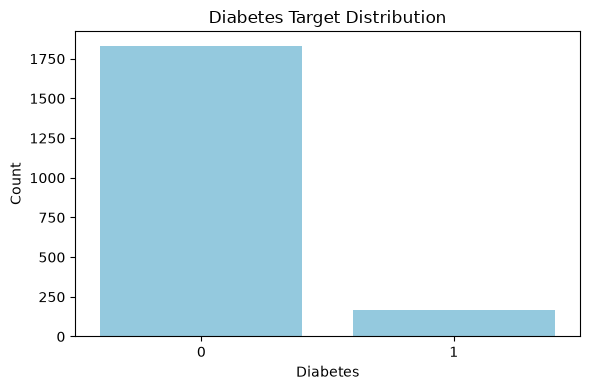

In [11]:
# Diabetes class distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=df["diabetes"], color="skyblue")
plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The target variable contains two classes, 0 for patients without diabetes and 1 for patients with diabetes. The classes are not equally distributed, so a stratified train-test split is used to maintain a similar class proportion in both sets.


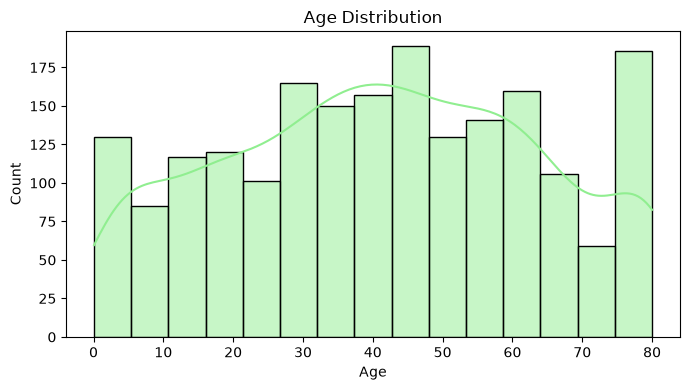

In [12]:
# Age distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["age"], kde=True, color="lightgreen")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The age distribution contains patients from different age groups, with more observations concentrated in the middle age ranges.


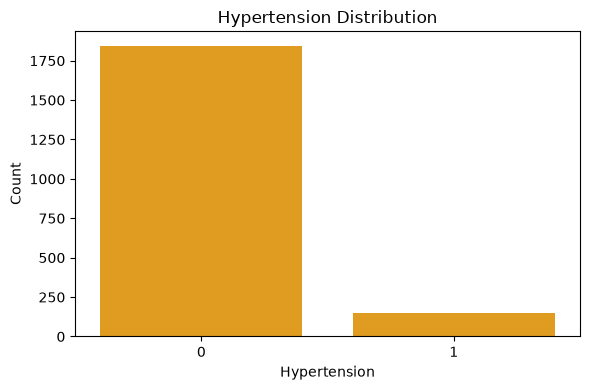

In [13]:
# Hypertension distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=df["hypertension"], color="orange")
plt.title("Hypertension Distribution")
plt.xlabel("Hypertension")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

Hypertension is a binary feature with values 0 and 1. Most observations have a value of 0, so the feature is imbalanced toward patients without hypertension.


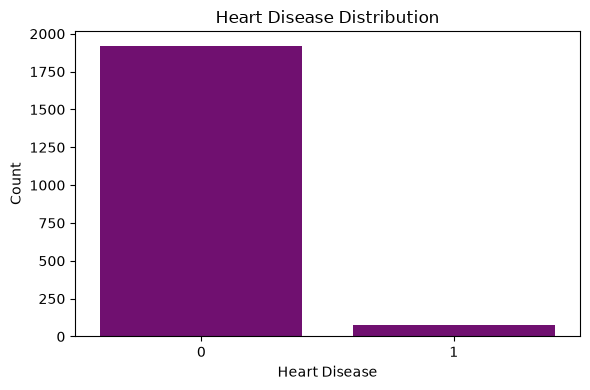

In [14]:
# Heart disease distribution

plt.figure(figsize=(6, 4))
sns.countplot(x=df["heart_disease"], color="purple")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

Heart disease is a binary feature, and most observations have a value of 0. This shows that heart disease is less common in this dataset than its absence.


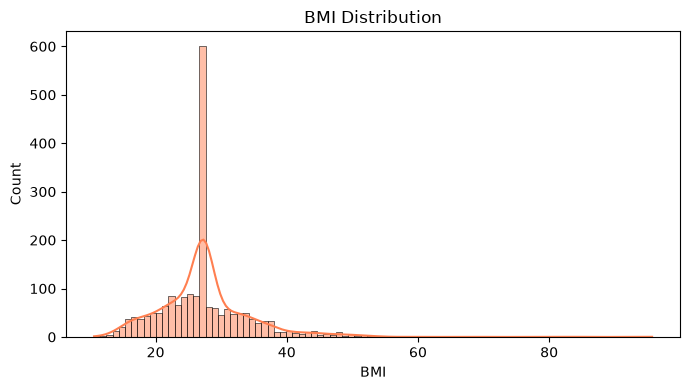

In [15]:
# BMI distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["bmi"], kde=True, color="coral")
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The BMI values are spread across a wide range, with most observations concentrated around the middle of the distribution and fewer observations at higher values.


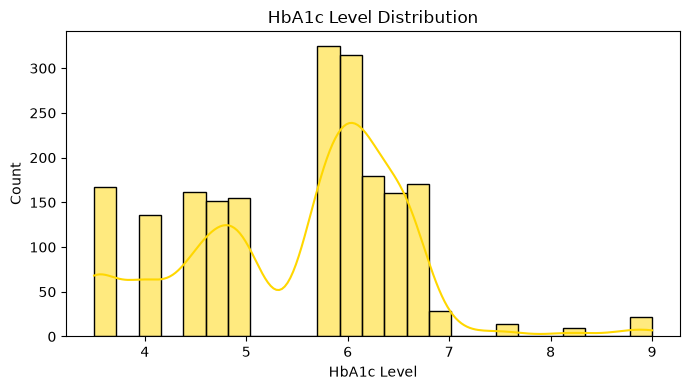

In [16]:
# HbA1c level distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["HbA1c_level"], kde=True, color="gold")
plt.title("HbA1c Level Distribution")
plt.xlabel("HbA1c Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The HbA1c level distribution shows that most observations are concentrated in a lower range, while some patients have higher HbA1c values.


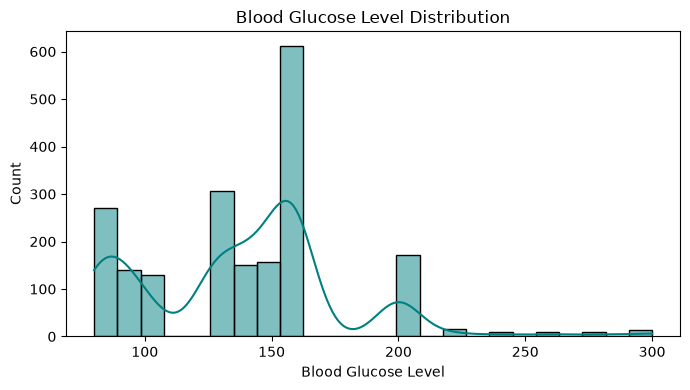

In [17]:
# Blood glucose level distribution

plt.figure(figsize=(7, 4))
sns.histplot(df["blood_glucose_level"], kde=True, color="teal")
plt.title("Blood Glucose Level Distribution")
plt.xlabel("Blood Glucose Level")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The blood glucose level distribution has a wider spread, with a smaller number of observations having higher glucose levels. These higher values are useful to examine in relation to diabetes.


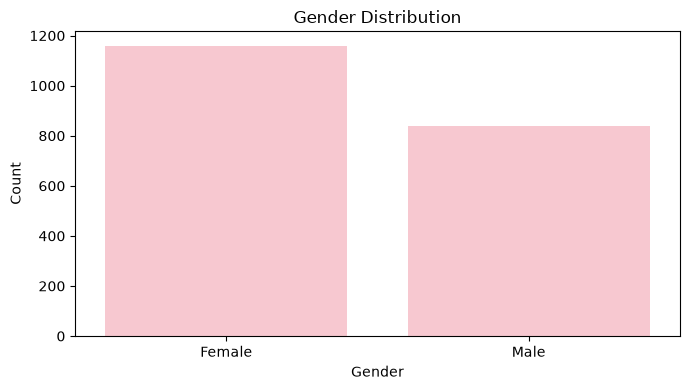

In [18]:
# Gender distribution

plt.figure(figsize=(7, 4))
sns.countplot(x=df["gender"], color="pink")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Insight

The gender categories have different frequencies, but the main categories are represented in the dataset.


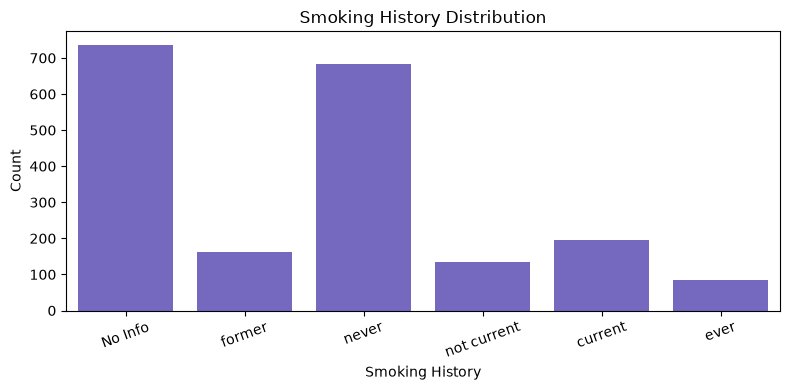

In [19]:
# Smoking history distribution

plt.figure(figsize=(8, 4))
sns.countplot(x=df["smoking_history"], color="slateblue")
plt.title("Smoking History Distribution")
plt.xlabel("Smoking History")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Insight

The smoking history categories are not evenly distributed. Some categories contain more patients than others.


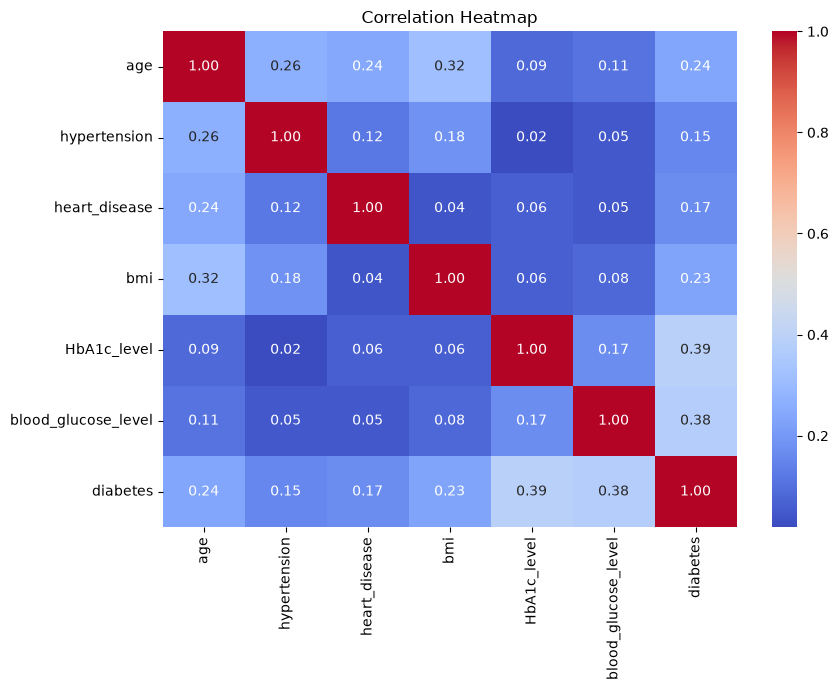

In [20]:
# Correlation heatmap

plt.figure(figsize=(9, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### Insight

The correlation heatmap shows the relationships among the numerical variables. Blood glucose level and HbA1c level show noticeable relationships with the diabetes target compared with several other numerical features.


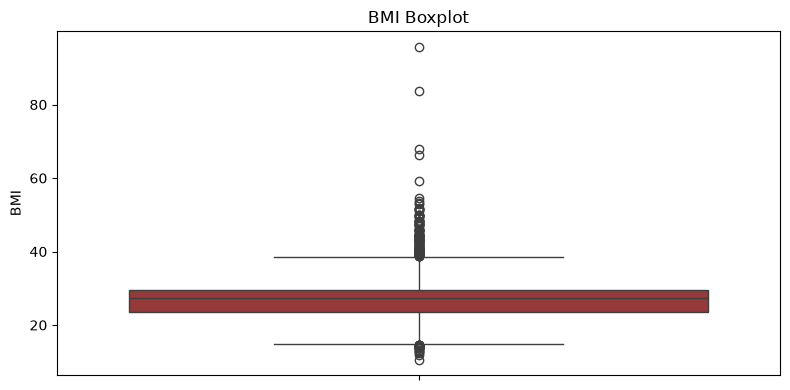

In [21]:
# BMI boxplot

plt.figure(figsize=(8, 4))
sns.boxplot(y=df["bmi"], color="brown")
plt.title("BMI Boxplot")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()


### Insight

The BMI boxplot shows the spread of the feature and highlights observations that are far from the main range. These values are checked using the IQR method before model training.


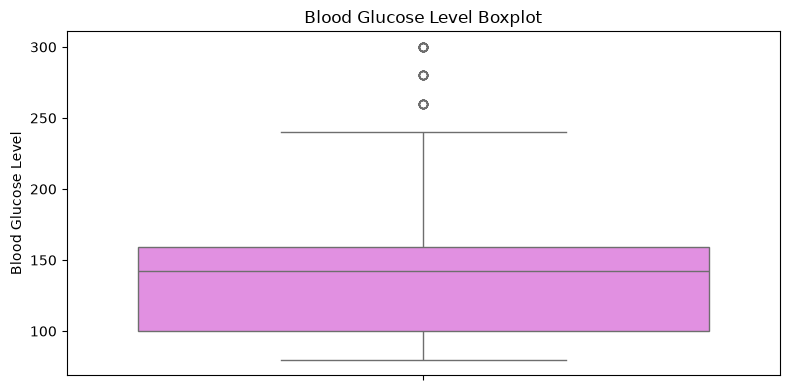

In [22]:
# Blood glucose level boxplot

plt.figure(figsize=(8, 4))
sns.boxplot(y=df["blood_glucose_level"], color="violet")
plt.title("Blood Glucose Level Boxplot")
plt.ylabel("Blood Glucose Level")
plt.tight_layout()
plt.show()


### Insight

The blood glucose boxplot shows a wider spread and some high-value observations. These observations are considered during the outlier treatment step.


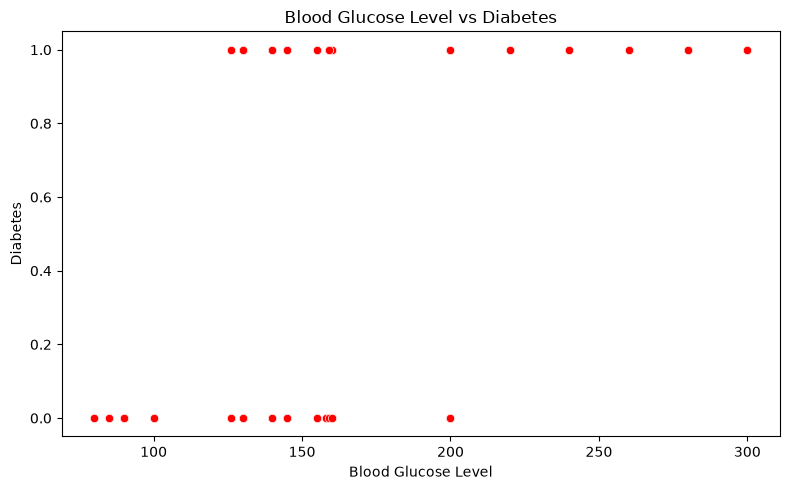

In [23]:
# Blood glucose level vs diabetes

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df["blood_glucose_level"],
    y=df[TARGET_COLUMN],
    color="red"
)
plt.title("Blood Glucose Level vs Diabetes")
plt.xlabel("Blood Glucose Level")
plt.ylabel("Diabetes")
plt.tight_layout()
plt.show()


### Insight

The scatter plot shows that diabetes-positive observations appear more frequently at higher blood glucose levels. This suggests that blood glucose level is an important feature for the classification problem.


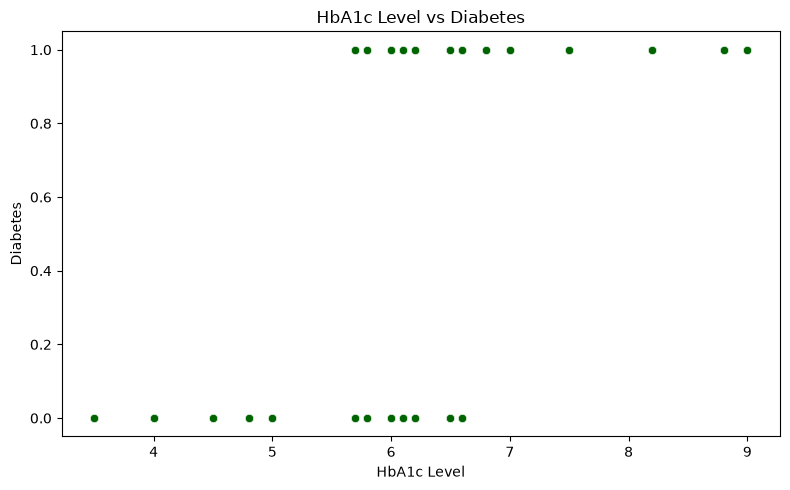

In [24]:
# HbA1c level vs diabetes

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df["HbA1c_level"],
    y=df[TARGET_COLUMN],
    color="darkgreen"
)
plt.title("HbA1c Level vs Diabetes")
plt.xlabel("HbA1c Level")
plt.ylabel("Diabetes")
plt.tight_layout()
plt.show()


### Insight

The scatter plot shows that diabetes-positive observations are more common at higher HbA1c levels. This indicates that HbA1c level has a useful relationship with the target variable.


In [25]:
# Check and treat outliers using the IQR method

outlier_cols = ["bmi", "HbA1c_level", "blood_glucose_level"]
outlier_summary = []
for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outliers Found": count
    })

    df[col] = df[col].clip(lower=lower, upper=upper)

pd.DataFrame(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outliers Found
0,bmi,14.66375,38.61375,143
1,HbA1c_level,2.70000,8.30000,22
2,blood_glucose_level,11.50000,247.50000,33


## Feature Engineering

The engineered feature combines blood glucose level and HbA1c level because both features describe blood sugar related information. Their interaction may provide additional information for the diabetes classification model.


In [26]:
# Create an engineered feature

df["glucose_hba1c_interaction"] = (df["blood_glucose_level"] * df["HbA1c_level"])


In [27]:
# Separate features and target

x = df.drop("diabetes", axis=1)
y = df[TARGET_COLUMN]

print("Features:")
print(x.head())
print("\nTarget:")
print(y.head())


Features:
   gender   age  hypertension  heart_disease smoking_history       bmi  \
0  Female  13.0             0              0         No Info  20.82000   
1  Female   3.0             0              0         No Info  21.00000   
2    Male  63.0             0              0          former  25.32000   
3  Female   2.0             0              0           never  17.43000   
4  Female  33.0             0              0     not current  38.61375   

   HbA1c_level  blood_glucose_level  glucose_hba1c_interaction  
0          5.8                126.0                      730.8  
1          5.0                145.0                      725.0  
2          3.5                200.0                      700.0  
3          6.1                126.0                      768.6  
4          6.2                200.0                     1240.0  

Target:
0    0
1    0
2    0
3    0
4    1
Name: diabetes, dtype: int64


In [28]:
# Identify numerical and categorical features

num_features = x.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = x.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical features:")
print(num_features)
print("\nCategorical features:")
print(cat_features)

Numerical features:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'glucose_hba1c_interaction']

Categorical features:
['gender', 'smoking_history']


C:\Users\LOQ\AppData\Local\Temp\ipykernel_9588\1555723503.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = x.select_dtypes(include=["object", "category"]).columns.tolist()


In [29]:
# Preprocessing

prep = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), num_features),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), cat_features)
    ]
)


In [30]:
# Same reproducible stratified 80:20 split used for Classification 1–5

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", x_train.shape)
print("Testing set:", x_test.shape)

Training set: (1596, 9)
Testing set: (400, 9)


In [31]:
# Create the baseline Random Forest Classifier
rf_model = Pipeline(
    steps=[
        ("preprocessing", prep),
        ("random_forest", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)
rf_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: f

In [32]:
# Train the baseline Random Forest model
rf_model.fit(x_train, y_train)
print("Baseline Random Forest model trained successfully.")

Baseline Random Forest model trained successfully.


In [33]:
# Make baseline predictions
rf_baseline_pred = rf_model.predict(x_test)
rf_baseline_prob = rf_model.predict_proba(x_test)[:, 1]
print("Baseline predictions:")
print(rf_baseline_pred[:10])

Baseline predictions:
[0 0 0 0 0 0 0 0 0 0]


In [34]:
# Calculate baseline evaluation metrics on the held-out test set
rf_baseline_accuracy = accuracy_score(y_test, rf_baseline_pred)
rf_baseline_precision = precision_score(y_test, rf_baseline_pred, zero_division=0)
rf_baseline_recall = recall_score(y_test, rf_baseline_pred, zero_division=0)
rf_baseline_f1 = f1_score(y_test, rf_baseline_pred, average="weighted", zero_division=0)
rf_baseline_auc = roc_auc_score(y_test, rf_baseline_prob)

baseline_results = pd.DataFrame([{
    "Version": "Baseline Random Forest",
    "Accuracy": rf_baseline_accuracy,
    "Precision": rf_baseline_precision,
    "Recall": rf_baseline_recall,
    "Weighted F1": rf_baseline_f1,
    "ROC-AUC": rf_baseline_auc
}])

print("Baseline Random Forest Performance")
display(baseline_results.round(4))

Baseline Random Forest Performance


,Version,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Baseline Random Forest,0.96,0.9474,0.5455,0.955,0.9444


## Hyperparameter Tuning

GridSearchCV tunes the number of trees (`n_estimators`), maximum tree depth (`max_depth`), and minimum samples needed to split an internal node (`min_samples_split`). The search uses only the training set and five-fold cross-validation. The held-out test set is used only for the final comparison.

In [35]:
# Tune Random Forest with cross-validation on training data only
rf_param_grid = {
    "random_forest__n_estimators": [100, 200],
    "random_forest__max_depth": [None, 15],
    "random_forest__min_samples_split": [2, 5]
}

rf_grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=1,
    refit=True,
    return_train_score=False,
    verbose=1
)
rf_grid_search.fit(x_train, y_train)
best_rf_model = rf_grid_search.best_estimator_

print("Best parameters:", rf_grid_search.best_params_)
print("Best mean cross-validation weighted F1:", round(rf_grid_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'random_forest__max_depth': None, 'random_forest__min_samples_split': 5, 'random_forest__n_estimators': 100}
Best mean cross-validation weighted F1: 0.9689


In [36]:
# Evaluate the tuned Random Forest on the held-out test set
rf_pred = best_rf_model.predict(x_test)
rf_prob = best_rf_model.predict_proba(x_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, average="weighted", zero_division=0)
rf_auc = roc_auc_score(y_test, rf_prob)

tuned_results = pd.DataFrame([{
    "Version": "Tuned Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "Weighted F1": rf_f1,
    "ROC-AUC": rf_auc
}])

print("Tuned Random Forest Performance on the Held-Out Test Set")
display(tuned_results.round(4))

rf_tuning_comparison = pd.concat([baseline_results, tuned_results], ignore_index=True)
print("Baseline versus tuned model (same held-out test set)")
display(rf_tuning_comparison.round(4))
print("Change in held-out weighted F1 after tuning:", round(rf_f1 - rf_baseline_f1, 4))

Tuned Random Forest Performance on the Held-Out Test Set


,Version,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Tuned Random Forest,0.9625,1.0,0.5455,0.9574,0.9302


Baseline versus tuned model (same held-out test set)


,Version,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Baseline Random Forest,0.9600,0.9474,0.5455,0.9550,0.9444
1,Tuned Random Forest,0.9625,1.0000,0.5455,0.9574,0.9302


Change in held-out weighted F1 after tuning: 0.0024


In [37]:
# Classification report for the tuned Random Forest
print("Tuned Random Forest Classification Report")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

Tuned Random Forest Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.96      1.00      0.98       367
    Diabetes       1.00      0.55      0.71        33

    accuracy                           0.96       400
   macro avg       0.98      0.77      0.84       400
weighted avg       0.96      0.96      0.96       400



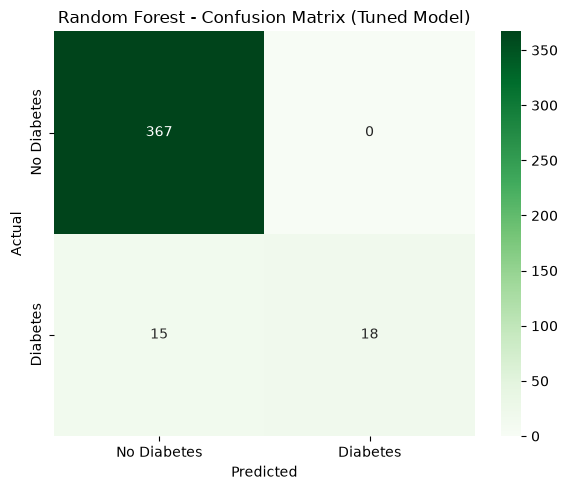

In [38]:
# Confusion Matrix for the tuned Random Forest
cm_rf = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Random Forest - Confusion Matrix (Tuned Model)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

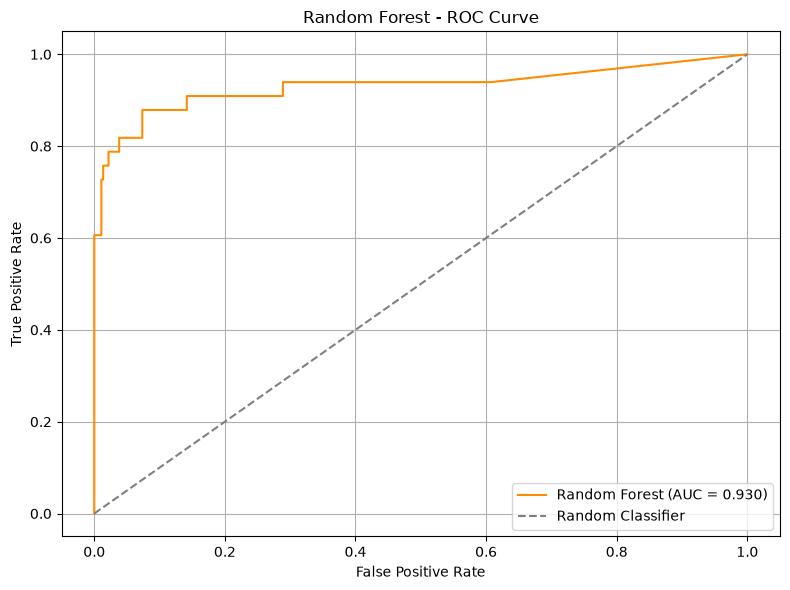

In [39]:
# ROC Curve for the tuned Random Forest
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
plt.figure(figsize=(8, 6))
plt.plot(
    rf_fpr,
    rf_tpr,
    color="darkorange",
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## Feature Importance

Random Forest provides a native feature-importance score based on the fitted trees. The plot shows the 15 most important transformed features; use it to describe model behaviour, not as evidence of causation.

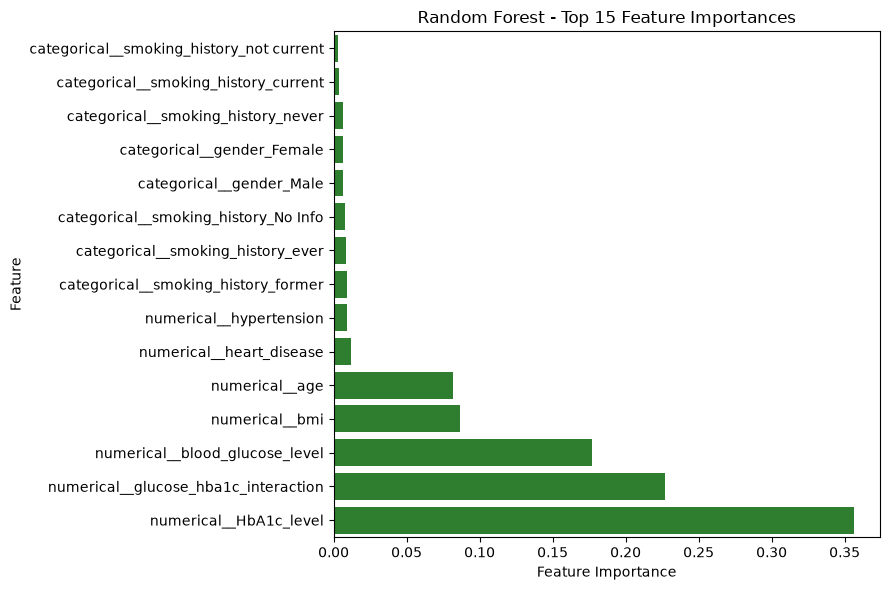

,Feature,Importance
0,numerical__HbA1c_level,0.356392
1,numerical__glucose_hba1c_interaction,0.227182
2,numerical__blood_glucose_level,0.176771
3,numerical__bmi,0.086450
4,numerical__age,0.081675
5,numerical__heart_disease,0.012092
6,numerical__hypertension,0.008999
7,categorical__smoking_history_former,0.008953
8,categorical__smoking_history_ever,0.008315
9,categorical__smoking_history_No Info,0.007693


In [40]:
# Feature importance for the tuned Random Forest
rf_feature_names = best_rf_model.named_steps["preprocessing"].get_feature_names_out()
rf_importances = best_rf_model.named_steps["random_forest"].feature_importances_

rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
}).sort_values("Importance", ascending=False)

top_rf_features = rf_importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
sns.barplot(
    data=top_rf_features,
    x="Importance",
    y="Feature",
    color="forestgreen"
)
plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(rf_importance_df.reset_index(drop=True))

## Save Results

The tuned model's held-out test metrics are saved to the same `classification_results.csv` used by the five Review 1 notebooks. Existing rows are preserved; rerunning this notebook replaces only the `Random Forest` row.

In [41]:
# Save tuned Random Forest metrics, predictions, and fitted model
import os
import joblib

os.makedirs("../results", exist_ok=True)
results_path = "../results/classification_results.csv"

rf_row = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "Weighted F1": rf_f1,
    "ROC-AUC": rf_auc
}])

if os.path.exists(results_path):
    saved = pd.read_csv(results_path)
    saved = saved[saved["Model"] != "Random Forest"]
    saved = pd.concat([saved, rf_row], ignore_index=True)
else:
    saved = rf_row.copy()

saved.to_csv(results_path, index=False)

os.makedirs("../results/predictions", exist_ok=True)
pd.DataFrame({
    "y_test": y_test.to_numpy(),
    "y_pred": rf_pred,
    "y_prob": rf_prob
}).to_csv("../results/predictions/Random Forest.csv", index=False)

os.makedirs("../models", exist_ok=True)
joblib.dump(best_rf_model, "../models/random_forest_classifier.joblib")

print("Results saved to:", results_path)
print("Predictions saved to ../results/predictions/Random Forest.csv")
print("Tuned model saved to ../models/random_forest_classifier.joblib")
display(saved.sort_values("Weighted F1", ascending=False).reset_index(drop=True))

Results saved to: ../results/classification_results.csv
Predictions saved to ../results/predictions/Random Forest.csv
Tuned model saved to ../models/random_forest_classifier.joblib


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Decision Tree,0.9625,1.000000,0.545455,0.957361,0.953596
1,Random Forest,0.9625,1.000000,0.545455,0.957361,0.930229
2,Support Vector Machine,0.9600,1.000000,0.515152,0.954027,0.926018
3,K-Nearest Neighbors,0.9550,0.894737,0.515152,0.949363,0.868095
4,Logistic Regression,0.9450,0.789474,0.454545,0.938111,0.943110
5,Gaussian Naive Bayes,0.9000,0.438596,0.757576,0.911643,0.935596


## Final Classification Comparison

This table combines the results currently saved by the classification notebooks. Run the remaining Part-B notebooks to include all ten classifiers in the final Review 2 comparison.

In [42]:
# Final comparison table
if os.path.exists(results_path):
    comparison = pd.read_csv(results_path)
    comparison = comparison.sort_values(
        "Weighted F1", ascending=False
    ).reset_index(drop=True)
else:
    comparison = rf_row.copy()

comparison

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Random Forest,0.9625,1.000000,0.545455,0.957361,0.930229
1,Decision Tree,0.9625,1.000000,0.545455,0.957361,0.953596
2,Support Vector Machine,0.9600,1.000000,0.515152,0.954027,0.926018
3,K-Nearest Neighbors,0.9550,0.894737,0.515152,0.949363,0.868095
4,Logistic Regression,0.9450,0.789474,0.454545,0.938111,0.943110
5,Gaussian Naive Bayes,0.9000,0.438596,0.757576,0.911643,0.935596
